In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
class TwoLayersPerceptron:
    def __init__(self, input_size, hidden_size, output_size, random_seed=None):
        if random_seed is not None:
            np.random.seed(random_seed)

        self.W1 = np.random.randn(input_size, hidden_size)    # Input to hidden
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size)   # Hidden to output
        self.b2 = np.zeros((1, output_size))

        self.loss_history = []

    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def _sigmoid_deriv(self, x):
        return x * (1 - x)

    def predict(self, X):
        z1 = np.dot(X, self.W1) + self.b1
        a1 = self._sigmoid(z1)
        z2 = np.dot(a1, self.W2) + self.b2

        output = z2
        return output

    def fit(self, X, y, learning_rate=0.01, epochs=100):
        for _ in range(epochs):
            # Forward pass
            z1 = np.dot(X, self.W1) + self.b1
            a1 = self._sigmoid(z1)
            z2 = np.dot(a1, self.W2) + self.b2

            output = z2

            # Backward pass
            error = y - output

            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

            d_output = error * 1

            error_hidden = d_output.dot(self.W2.T)
            d_hidden = error_hidden * self._sigmoid_deriv(a1)

            # Update weights and biases
            self.W2 += a1.T.dot(d_output) * learning_rate
            self.b2 += np.sum(d_output, axis=0, keepdims=True) * learning_rate
            self.W1 += X.T.dot(d_hidden) * learning_rate
            self.b1 += np.sum(d_hidden, axis=0, keepdims=True) * learning_rate

    def plot_loss(self):
      plt.plot(self.loss_history, label='Training Loss (MSE)')
      plt.title('Evolución del Error durante el Entrenamiento')
      plt.xlabel('Épocas')
      plt.ylabel('Error Cuadrático Medio')
      plt.legend()
      plt.grid(True)
      plt.show()

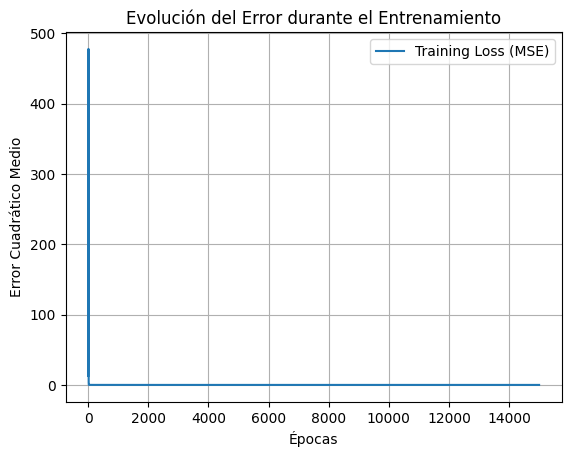

In [4]:
df = pd.read_parquet('data_train.parquet')

X_train = df[['X']].values
y_train = df[['Y']].values

input_size = X_train.shape[1]
hidden_size = 100
output_size = 1

modelo = TwoLayersPerceptron(input_size, hidden_size, output_size, random_seed=42)

# Entrenar
modelo.fit(X_train, y_train, learning_rate=0.001, epochs=15000)

# Graficar el resultado
modelo.plot_loss()

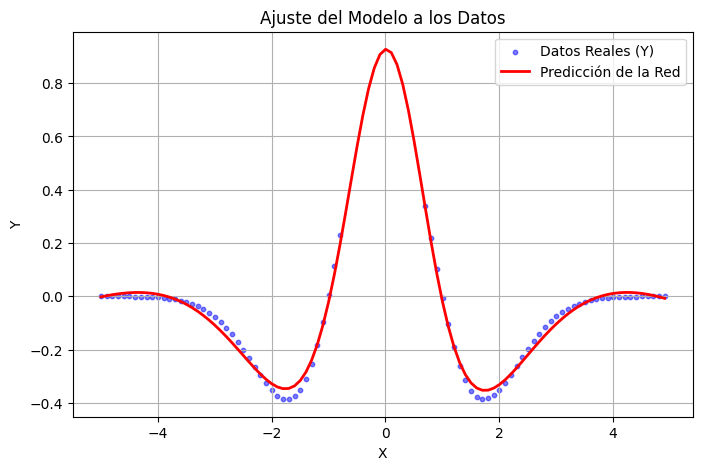

In [5]:
# Graficar los datos reales frente a la predicción del modelo
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='Datos Reales (Y)', color='blue', alpha=0.5, s=10)

# Generamos puntos X ordenados para dibujar una línea continua de predicción
X_linea = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
Y_prediccion = modelo.predict(X_linea)

plt.plot(X_linea, Y_prediccion, label='Predicción de la Red', color='red', linewidth=2)
plt.title('Ajuste del Modelo a los Datos')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()